# 

In [ ]:
import sys, io as _io
from pathlib import Path
sys.path.insert(0, str(Path('..').resolve()))

import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
import numpy as np
from mpl_toolkits.mplot3d import Axes3D
from dataclasses import dataclass, field
from datetime import datetime
from typing import Optional, Dict

import sqlite3
import database as db

In [ ]:
# ── Data source switch ────────────────────────────────────────────────────────
# 'vnstock'  : fetch VN30 index price live from VCI (requires API)
# 'db'       : read from stock_data.db — no API call needed
#              also adds pe_ratio column for strategy signals
DATA_SOURCE   = 'db'
INDEX_SYMBOL  = 'VN30'
VNSTOCK_START = '2012-01-01'
VNSTOCK_END   = '2026-07-10'


def load_df(source: str) -> pd.DataFrame:
    """
    Returns DataFrame with [time, close] always present.
    'db' source also adds [pe_ratio] from stock_data.db.
    'close' is in index points (~400-2000 range) — downstream code
    multiplies by 1000 to work in VND-like scale.
    """
    if source == 'vnstock':
        from vnstock import Quote
        quote = Quote(symbol=INDEX_SYMBOL, source='VCI')
        df = quote.history(start=VNSTOCK_START, end=VNSTOCK_END, interval='1D')
        df = df.reset_index(drop=True)
        df['time'] = pd.to_datetime(df['time'])
        return df

    if source == 'db':
        prices = db.load_index_prices(INDEX_SYMBOL).reset_index()
        prices = prices.rename(columns={'date': 'time'})

        con = sqlite3.connect(db.DB_PATH)
        pe = pd.read_sql_query(
            'SELECT date, pe_ratio FROM pe_vn30 WHERE pe_ratio IS NOT NULL ORDER BY date',
            con, parse_dates=['date']
        )
        con.close()
        pe = pe.rename(columns={'date': 'time'})

        df = prices.merge(pe, on='time', how='left')
        df['pe_ratio'] = df['pe_ratio'].ffill()
        return df.reset_index(drop=True)

    raise ValueError(f'Unknown source: {source}')


df = load_df(DATA_SOURCE)
df = df.reset_index(drop=True)
print(f'Source : {DATA_SOURCE}')
print(f'Rows   : {len(df)}')
print(f'Range  : {df["time"].iloc[0].date()} -> {df["time"].iloc[-1].date()}')
print(f'Close  : {df["close"].min():.0f} - {df["close"].max():.0f}')
df

In [ ]:
@dataclass
class RangeDaysClose:
    localTop: float
    localAvg: float
    localBottom: float
    p25: float = 0.0
    median: float = 0.0
    p75: float = 0.0
    pe_p25: float = 0.0
    pe_median: float = 0.0
    pe_p75: float = 0.0

@dataclass
class IndexCloses:
    rangeDayCloses: dict[int, RangeDaysClose] = field(default_factory=dict)
    rangeDayClosesPos: dict[int, RangeDaysClose] = field(default_factory=dict)

In [ ]:
cal_range_close: dict[int, IndexCloses] = {}

firstRow = df.head(1)
firstClose = firstRow['close'].values[0] * 1000
firstDate = firstRow['time'].values[0]
firstDate = pd.Timestamp(firstDate)

for index, row in df.iterrows():
    indexCloses = IndexCloses()
    cal_range_close[index] = indexCloses

    for rangeDays in range(1000, 1001):
        # ── Backward window ───────────────────────────────────────────────────
        fromIndex = max(0, index - rangeDays)
        toIndex = index
        lastNRows = df.iloc[fromIndex:toIndex]

        if not lastNRows.empty:
            closes = lastNRows['close'] * 1000
            localTop    = closes.max()
            localBottom = closes.min()
            localAvg    = closes.mean()
            p25         = closes.quantile(0.25)
            median      = closes.quantile(0.50)
            p75         = closes.quantile(0.75)

            pe_vals = lastNRows['pe_ratio'].dropna() if 'pe_ratio' in lastNRows.columns else pd.Series(dtype=float)
            pe_p25    = pe_vals.quantile(0.25) if not pe_vals.empty else 0.0
            pe_median = pe_vals.quantile(0.50) if not pe_vals.empty else 0.0
            pe_p75    = pe_vals.quantile(0.75) if not pe_vals.empty else 0.0
        else:
            localTop = localBottom = localAvg = firstClose
            p25 = median = p75 = firstClose
            pe_p25 = pe_median = pe_p75 = 0.0

        indexCloses.rangeDayCloses[rangeDays] = RangeDaysClose(
            localTop=localTop, localAvg=localAvg, localBottom=localBottom,
            p25=p25, median=median, p75=p75,
            pe_p25=pe_p25, pe_median=pe_median, pe_p75=pe_p75,
        )

        # ── Forward window ────────────────────────────────────────────────────
        fromIndex = index + 1
        toIndex = min(len(df), index + 1 + rangeDays)
        lastNRows = df.iloc[fromIndex:toIndex]

        if not lastNRows.empty:
            closes = lastNRows['close'] * 1000
            localTop    = closes.max()
            localBottom = closes.min()
            localAvg    = closes.mean()
            p25         = closes.quantile(0.25)
            median      = closes.quantile(0.50)
            p75         = closes.quantile(0.75)

            pe_vals = lastNRows['pe_ratio'].dropna() if 'pe_ratio' in lastNRows.columns else pd.Series(dtype=float)
            pe_p25    = pe_vals.quantile(0.25) if not pe_vals.empty else 0.0
            pe_median = pe_vals.quantile(0.50) if not pe_vals.empty else 0.0
            pe_p75    = pe_vals.quantile(0.75) if not pe_vals.empty else 0.0
        else:
            localTop = localBottom = localAvg = firstClose
            p25 = median = p75 = firstClose
            pe_p25 = pe_median = pe_p75 = 0.0

        indexCloses.rangeDayClosesPos[rangeDays] = RangeDaysClose(
            localTop=localTop, localAvg=localAvg, localBottom=localBottom,
            p25=p25, median=median, p75=p75,
            pe_p25=pe_p25, pe_median=pe_median, pe_p75=pe_p75,
        )

In [110]:
cal_range_close[20].rangeDayCloses[1000]

RangeDaysClose(localTop=503540.0, localAvg=465866.5000000001, localBottom=443540.0)

In [111]:
totalClose = 0
totalMonths = 0

monthAdd = 0
yearAdd = 0
for index, row in df.iterrows():
    close = row['close'] * 1000
    timeCol = row['time']
    month = timeCol.month;
    year = timeCol.year;
    day = timeCol.day

    if(monthAdd != month or yearAdd != year):
        totalClose += close
        totalMonths += 1
        monthAdd = month
        yearAdd = year

print(totalMonths)
print(totalClose / totalMonths)

170
946333.7058823529


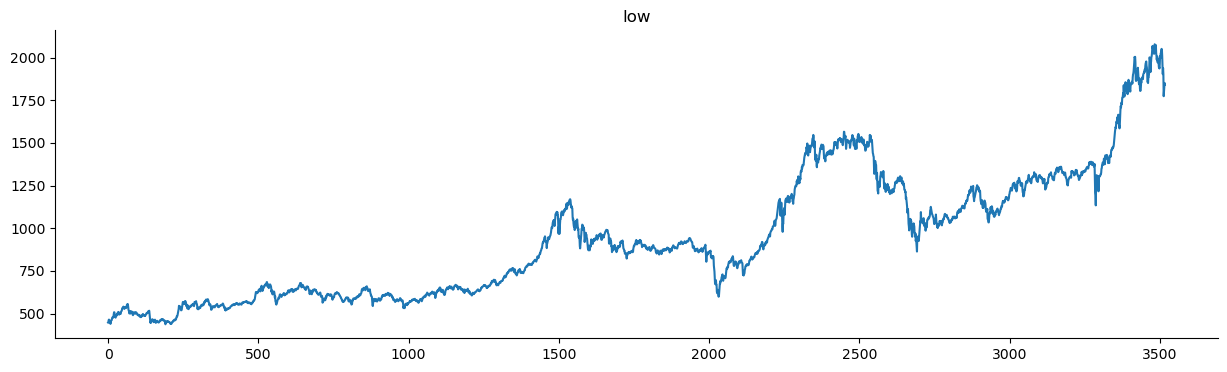

In [112]:

df['low'].plot(kind='line', figsize=(15, 4), title='low')
plt.gca().spines[['top', 'right']].set_visible(False)

In [113]:
@dataclass
class SellInfo:
    index: int = 0
    time: str = ""
    close: float = 0.0
    localBottom: float = 0.0
    localBottomDate: str = ""
    sellShare: float = 0.0
    sellCapital: float = 0.0
    sellFinal: float = 0.0
    sellGrowthRatito: float = 0.0

@dataclass
class ReinvestInfo:
    index: int = 0
    time: str = ""
    close: float = 0.0
    averageProfitPrice: float = 0.0
    reInvestShare: float = 0.0
    reInvestFinal: float = 0.0
    reInvestCapital: float = 0.0

@dataclass
class BuyedInfo:
    index: int = 0
    time: str = ""
    close: float = 0.0
    localTop: float = 0.0
    localTopDate: str = ""
    finalBuy: float = 0.0
    numberOfShareCanBy: float = 0.0
   

@dataclass
class DepositAddInfo:
    index: int = 0
    time: str = ""
    close: float = 0.0
    totalReserveInterest: float = 0

class InvestmentTracker:
    def __init__(self):
        self.totalShare = 0
        self.totalCapital = 0
        self.totalCurrentCapital = 0

        self.intervalAmount = 0
        
        self.dateAddInterval = None
        self.dateInvestInterval = None
        self.dateDepositAdded = None
        self.totalMonths = 0

        self.totalReserveShare = 0
        self.totalReserveCapital = 0
        self.totalReserveFinal = 0
        
        self.buyedInfos: list[BuyedInfo] = []
        self.sellInfos: list[SellInfo] = []
        self.reinvestInfos: list[ReinvestInfo] = []
        self.depositAddInfos: list[DepositAddInfo] = []

        self.lastBuyIndex = 0
        self.lastSellIndex = 0
        self.lastReinvestIndex = 0

    def add_sell_info(self, info: SellInfo):
        self.sellInfos.append(info)

    def add_reinvest_info(self, info: ReinvestInfo):
        self.reinvestInfos.append(info)

    def add_buyed_info(self, info: BuyedInfo):
        self.buyedInfos.append(info)

    def add_depositAdd_info(self, info: DepositAddInfo):
        self.depositAddInfos.append(info)

In [114]:
class Sellor:
    def sell(self, tracker, sellFinal, index, close, isPrint):
        totalFinal = tracker.totalShare * close

        if(tracker.totalShare <= 0 or tracker.totalCapital <= 0):
            return
        if(sellFinal <= 0):
            return

        tracker.lastSellIndex = index
        
        sellShare = sellFinal * tracker.totalShare / totalFinal
        sellCapital = sellFinal * tracker.totalCapital / totalFinal
        sellCurrentCapital = sellFinal * tracker.totalCurrentCapital / totalFinal
    
        tracker.totalReserveShare += sellShare
        tracker.totalReserveCapital += sellCapital
        tracker.totalReserveFinal += sellFinal
    
        tracker.totalShare -= sellShare
        tracker.totalCapital -= sellCapital
        tracker.totalCurrentCapital -= sellCurrentCapital
        
        sellGrowthRatito = (sellFinal - sellCapital) / sellCapital * 100
        sellcurrentGrowthRatito = (sellFinal - sellCurrentCapital) / sellCurrentCapital * 100
        totalReserveGrowthRatio = (tracker.totalReserveFinal - tracker.totalReserveCapital) / tracker.totalReserveCapital * 100
        sellInfo = SellInfo(
            index=index,
            close=close,
            sellShare=sellShare,
            sellCapital=sellCapital,
            sellFinal=sellFinal,
            sellGrowthRatito=sellGrowthRatito
        )
        tracker.add_sell_info(sellInfo)
    
        if isPrint:
            print(f'''-------------------------------------------------------------''')
            print(f'''sell --- index: {index}, month: {tracker.totalMonths}, close: {close}, sellShare: {sellShare}, sellFinal: {sellFinal}, sellShare: {sellShare}, sellGrowthRatito: {sellGrowthRatito}% sellcurrentGrowthRatito: {sellcurrentGrowthRatito}%''')


class Reinvestor:
    def reinvest(self, tracker, reInvestFinal, index, close, isPrint):

        tracker.lastReinvestIndex = index
        
        reInvestShare = reInvestFinal *  tracker.totalReserveShare / tracker.totalReserveFinal
        reInvestCapital = reInvestFinal * tracker.totalReserveCapital / tracker.totalReserveFinal

        tracker.totalReserveShare -= reInvestShare
        tracker.totalReserveCapital -= reInvestCapital
        tracker.totalReserveFinal -= reInvestFinal

        tracker.totalCapital += reInvestCapital
        tracker.totalCurrentCapital += reInvestFinal
        reinvestShareCanBy = reInvestFinal / (close)
        tracker.totalShare += reinvestShareCanBy

        tracker.add_reinvest_info(ReinvestInfo(
            index=index,
            close=close,
            reInvestShare=reInvestShare,
            reInvestFinal=reInvestFinal,
            reInvestCapital=reInvestCapital,
        ))

        if isPrint:
            print(f'''-------------------------------------------------------------''')
            print(f'reinvest --- index: {index}, month: {tracker.totalMonths}, close: {close}, close {close}, reInvestCapital: {reInvestCapital}, reInvestFinal {reInvestFinal}')

class Buyer:
    def buy(self, tracker, finalBuy, reinvestFinal, index, close, isPrint):
        if(finalBuy > 0):

            tracker.lastBuyIndex = index

            tracker.intervalAmount -= finalBuy

            tracker.totalCapital += finalBuy
            tracker.totalCurrentCapital += finalBuy
            numberOfShareCanBy = finalBuy / (close)
            tracker.totalShare += numberOfShareCanBy

            tracker.add_buyed_info(BuyedInfo(
                index=index,
                close=close,
                finalBuy=finalBuy,
                numberOfShareCanBy=numberOfShareCanBy,
            ))

        # if isPrint and (availableBuyMoney > 0 or reinvestFinal > 0):
        #     print(f'''buy --- index: {index} close: {close}, availableBuyMoney: {availableBuyMoney}, reinvestFinal: {reinvestFinal}''')


class DepositAdder:
    def add(self, tracker, index, depositPercent, now, isPrint):
        month = now.month;
        year = now.year;
        day = now.day;

        
        if tracker.dateDepositAdded == None or (year > tracker.dateDepositAdded.year) or (year == tracker.dateDepositAdded.year and month > tracker.dateDepositAdded.month):
            tracker.dateDepositAdded = now

            totalReserveInterest = (tracker.totalReserveFinal) * (depositPercent / 100) / 12
            tracker.totalReserveFinal += totalReserveInterest

            # if isPrint:
            #     print(f'''adddeposit --- index: {index} close: {close}, availableMoneyInterest: {availableMoneyInterest}, totalProfitInterest: {totalProfitInterest}''')
            
            tracker.add_depositAdd_info(DepositAddInfo(
                index=index,
                close=close,
                totalReserveInterest=totalReserveInterest
            ))

@dataclass
class DeltaToActionMatrix():
    rangeDays: int = 0
    fromPercent: float = 0
    toPercent: float = 0
    actionPercent: float = 0

In [115]:
class SellStrategy:
    def considerSell(self, tracker: InvestmentTracker, index, close, cal_range_close, isPrint):
        pass

@dataclass
class SellTopStrategy(SellStrategy):
    percentSell: float = 0
    def considerSell(self, tracker: InvestmentTracker, index, close, cal_range_close, isPrint):
        if(tracker.totalCurrentCapital > 0 and tracker.totalShare > 0):
            totalFinal = tracker.totalShare * close
            increasePercent = (totalFinal - tracker.totalCurrentCapital) / tracker.totalCurrentCapital
            targetPercent = self.percentSell / 100
            deviationPercent = 0
            
            if(increasePercent > targetPercent - deviationPercent):
                sellFinal = totalFinal
                
                sellor = Sellor()
                sellor.sell(tracker, sellFinal, index, close, isPrint)

@dataclass
class SellTopOfBottomStrategy(SellStrategy):
    firstLocalBottom: float
    percentSell: float = 0
    localRangeDays: int = 0
    def considerSell(self, tracker: InvestmentTracker, index, close, cal_range_close, isPrint):
        if(tracker.totalCurrentCapital > 0 and tracker.totalShare > 0):
            localBottom = self.firstLocalBottom
    
            if(index in cal_range_close):
                if(self.localRangeDays in cal_range_close[index].rangeDayCloses):
                    localBottom = cal_range_close[index].rangeDayCloses[self.localRangeDays].localBottom
            increasePercent = (close - localBottom) / localBottom
            targetPercent = self.percentSell / 100
            if(increasePercent > targetPercent):
                totalFinal = tracker.totalShare * close
                sellFinal = totalFinal
                
                sellor = Sellor()
                sellor.sell(tracker, sellFinal, index, close, isPrint)

@dataclass
class SellProphetStrategy(SellStrategy):
    df: pd.DataFrame
    localRangeDays: int = 1
    percentSell: float = 0
    
    def considerSell(self, tracker: InvestmentTracker, index, close, cal_range_close, isPrint):
        if(index in cal_range_close):
            if(self.localRangeDays in cal_range_close[index].rangeDayClosesPos):
                localTop = cal_range_close[index].rangeDayClosesPos[self.localRangeDays].localTop

                if (close >= localTop) :
                    totalFinal = tracker.totalShare * close
                    sellFinal = totalFinal
                    
                    sellor = Sellor()
                    sellor.sell(tracker, sellFinal, index, close, isPrint)


@dataclass
class SellPartialStrategy(SellStrategy):
    firstLocalBottom: float
    growthToAllocations: list[DeltaToActionMatrix] = field(default_factory=list)
    lastIndexSell: int = 0
    def considerSell(self, tracker: InvestmentTracker, index, close, cal_range_close, isPrint):
        
        if(tracker.totalCurrentCapital <= 0 or tracker.totalShare <= 0):
            return
            
        localBottom = self.firstLocalBottom

        for growthToAllocation in self.growthToAllocations:
            if(growthToAllocation.rangeDays in cal_range_close[index].rangeDayCloses):
                localBottom = cal_range_close[index].rangeDayCloses[growthToAllocation.rangeDays].localBottom
        
                increasePercent = (close - localBottom) / localBottom * 100

                if(index > 4500):
                    print(index, localBottom, close, growthToAllocation.rangeDays, increasePercent, growthToAllocation.fromPercent, growthToAllocation.toPercent)
                 
                if growthToAllocation.fromPercent <= increasePercent and growthToAllocation.toPercent > increasePercent:
                   
                    if(index - self.lastIndexSell >= 10):
                        self.lastIndexSell = index
                        partialProfit = tracker.totalShare * close * (growthToAllocation.actionPercent / 100)
                
                        sellFinal = partialProfit
                        sellor = Sellor()
                        sellor.sell(tracker, sellFinal, index, close, isPrint)
                        return

@dataclass
class SellTopOfMA1000Strategy(SellStrategy):
    firstLocalBottom: float
    percentSell: float = 0
    def considerSell(self, tracker: InvestmentTracker, index, close, cal_range_close, isPrint):
        if(tracker.totalCurrentCapital > 0 and tracker.totalShare > 0):
            localBottom = self.firstLocalBottom
            if(index in cal_range_close):
                if(index > 1000):
                    if(1000 in cal_range_close[index].rangeDayCloses):
                        localBottom = cal_range_close[index].rangeDayCloses[1000].localAvg
                        
                        increasePercent = (close - localBottom) / localBottom
                        targetPercent = self.percentSell / 100
                        if(increasePercent > targetPercent):
                            
                            totalFinal = tracker.totalShare * close
                            sellFinal = totalFinal
                            
                            sellor = Sellor()
                            sellor.sell(tracker, sellFinal, index, close, isPrint)

In [116]:
class ReinvestStrategy:
    def considerReinvest(self, tracker: InvestmentTracker, index, close, cal_range_close, isPrint):
        pass

@dataclass
class ReInvestBottomStrategy(ReinvestStrategy):
    def considerReinvest(self, tracker: InvestmentTracker, index, close, cal_range_close, isPrint):
        if(tracker.totalReserveFinal > 0):
            averageReservePrice = tracker.totalReserveFinal / (tracker.totalReserveShare if tracker.totalReserveShare > 0 else 1)
            decreasePercent = (averageReservePrice - close) / averageReservePrice
            targetPercent = self.percentReinvest / 100
            deviationPercent = 0

            
            if(decreasePercent > targetPercent - deviationPercent):
                reInvestFinal = tracker.totalReserveFinal
                
                reinvestor = Reinvestor()
                reinvestor.reinvest(tracker, reInvestFinal, index, close, isPrint)

@dataclass
class ReInvestBottomOfTopStrategy(ReinvestStrategy):
    firstLocalTop: float
    localRangeDays: int = 1
    decreasePercent: float = 1
    def considerReinvest(self, tracker: InvestmentTracker, index, close, cal_range_close, isPrint):
        if(tracker.totalReserveFinal > 0):
            localTop = self.firstLocalTop
    
            if(index in cal_range_close):
                if(self.localRangeDays in cal_range_close[index].rangeDayCloses):
                    localTop = cal_range_close[index].rangeDayCloses[self.localRangeDays].localTop
    
            if (close < localTop) and ((localTop - close) / localTop) > (self.decreasePercent / 100):
                reInvestFinal = tracker.totalReserveFinal
                
                reinvestor = Reinvestor()
                reinvestor.reinvest(tracker, reInvestFinal, index, close, isPrint)

@dataclass
class ReInvestProphetStrategy(ReinvestStrategy):
    df: pd.DataFrame
    localRangeDays: int = 1
    
    def considerReinvest(self, tracker: InvestmentTracker, index, close, cal_range_close, isPrint):
        if(index in cal_range_close):
            if(self.localRangeDays in cal_range_close[index].rangeDayClosesPos):
                localBottom = cal_range_close[index].rangeDayClosesPos[self.localRangeDays].localBottom

                if (close <= localBottom) :
                    reInvestFinal = tracker.totalReserveFinal
                
                    reinvestor = Reinvestor()
                    reinvestor.reinvest(tracker, reInvestFinal, index, close, isPrint)


@dataclass
class ReInvestPartialStrategy(ReinvestStrategy):
    deltaToActions: list[DeltaToActionMatrix] = field(default_factory=list)
    lastIndexAction: int = 0
    def considerReinvest(self, tracker: InvestmentTracker, index, close, cal_range_close, isPrint):
        if(tracker.totalReserveFinal <= 0):
            return

        for deltaToAction in self.deltaToActions:
            if(deltaToAction.rangeDays in cal_range_close[index].rangeDayCloses):
                localTop = cal_range_close[index].rangeDayCloses[deltaToAction.rangeDays].localTop
        
                deltaPercent = (localTop - close) / localTop * 100

                if deltaToAction.fromPercent <= deltaPercent and deltaToAction.toPercent > deltaPercent:
                    if(index - self.lastIndexAction >= 10):
                        self.lastIndexAction = index

                        partialVolumn = tracker.totalReserveFinal * (deltaToAction.actionPercent / 100)
                
                        reinvestor = Reinvestor()
                        reinvestor.reinvest(tracker, partialVolumn, index, close, isPrint)
                        
                        return

@dataclass
class ReInvestUnderMA1000Strategy(ReinvestStrategy):
    
    def considerReinvest(self, tracker: InvestmentTracker, index, close, cal_range_close, isPrint):
        if(tracker.totalReserveFinal <= 0):
            return
            
        if(index in cal_range_close):
                if(index > 1000):
                    if(1000 in cal_range_close[index].rangeDayCloses):
                        ma1000 = cal_range_close[index].rangeDayCloses[1000].localAvg
                        if (close < ma1000):
                            reInvestFinal = tracker.totalReserveFinal
                            
                            reinvestor = Reinvestor()
                            reinvestor.reinvest(tracker, reInvestFinal, index, close, isPrint)

@dataclass
class ReInvestUnderMA1000OrMaxHoldTimeStrategy(ReinvestStrategy):
    maxHoldTime: int = 10000000000
    def considerReinvest(self, tracker: InvestmentTracker, index, close, cal_range_close, isPrint):
        if(tracker.totalReserveFinal <= 0):
            return
            
        if(index in cal_range_close):
                if(index > 1000):
                    if(1000 in cal_range_close[index].rangeDayCloses):
                        ma1000 = cal_range_close[index].rangeDayCloses[1000].localAvg
                        if (close < ma1000):
                            reInvestFinal = tracker.totalReserveFinal
                            
                            reinvestor = Reinvestor()
                            reinvestor.reinvest(tracker, reInvestFinal, index, close, isPrint)

                            return

        if(tracker.lastSellIndex > 0 and (index - tracker.lastSellIndex) > self.maxHoldTime):
            reInvestFinal = tracker.totalReserveFinal
                            
            reinvestor = Reinvestor()
            reinvestor.reinvest(tracker, reInvestFinal, index, close, isPrint)

            return

In [163]:
class BuyStrategy:
    def considerBuy(self, tracker: InvestmentTracker, index, close, cal_range_close, isPrint):
        pass

@dataclass
class BuyIntervalStrategy(BuyStrategy):
    def considerBuy(self, tracker: InvestmentTracker, index, close, cal_range_close, isPrint):
        availableBuyMoney = tracker.intervalAmount
        
        buyer = Buyer()
        buyer.buy(tracker, availableBuyMoney, 0, index, close, isPrint)

@dataclass
class BuyBottomStrategy(BuyStrategy):
    df: pd.DataFrame
    firstLocalTop: float
    firstLocalTopDate: datetime
    localRangeDays: int = 1
    decreasePercent: float = 1
    
    def considerBuy(self, tracker: InvestmentTracker, index, close, cal_range_close, isPrint):
        localTop = self.firstLocalTop
        localTopdate = self.firstLocalTopDate

        if(index in cal_range_close):
            if(self.localRangeDays in cal_range_close[index].rangeDayCloses):
                localTop = cal_range_close[index].rangeDayCloses[self.localRangeDays].localTop

        if (close < localTop) and ((localTop - close) / localTop) > (self.decreasePercent / 100):
            availableBuyMoney = tracker.intervalAmount
        
            buyer = Buyer()
            buyer.buy(tracker, availableBuyMoney, 0, index, close, isPrint)
            

@dataclass
class BuyMAStrategy(BuyStrategy):
    df: pd.DataFrame
    firstLocalAvg: float
    localRangeDays: int = 1
    decreasePercent: float = 1
    
    def considerBuy(self, tracker: InvestmentTracker, index, close, cal_range_close, isPrint):
        localAvg = self.firstLocalAvg

        # maxDistanceFromPresent = self.localRangeDays if self.localRangeDays < index else index
        # fromIndex = index - maxDistanceFromPresent - 1
        # if fromIndex < 0:
        #     fromIndex = 0
        # toIndex = index

        # lastNRows = self.df.iloc[fromIndex : toIndex]  # Get last rows

        # if not lastNRows.empty:
        #     avg_close_value = lastNRows['close'].mean()
        #     localAvg = avg_close_value * 1000

        if(index in cal_range_close):
            if(self.localRangeDays in cal_range_close[index].rangeDayCloses):
                localAvg = cal_range_close[index].rangeDayCloses[self.localRangeDays].localAvg

        if (close < localAvg) and ((localAvg - close) / localAvg) > (self.decreasePercent / 100):
            availableBuyMoney = tracker.intervalAmount
        
            buyer = Buyer()
            buyer.buy(tracker, availableBuyMoney, 0, index, close, isPrint)

       

@dataclass
class BuyUptrendStrategy(BuyStrategy):
    df: pd.DataFrame
    localRangeDays1: int = 1
    localRangeDays2: int = 1

    def considerBuy(self, tracker: InvestmentTracker, index, close, cal_range_close, isPrint):
        if(index in cal_range_close):
            if(self.localRangeDays1 in cal_range_close[index].rangeDayCloses):
                localAvg1 = cal_range_close[index].rangeDayCloses[self.localRangeDays1].localAvg

                if (close > localAvg1):
                    intervalAmount = tracker.availableMoney
                    buyer = Buyer()
                    buyer.buy(tracker, availableBuyMoney, 0, index, close, isPrint)
                else:
                    if(self.localRangeDays2 in cal_range_close[index].rangeDayCloses):
                        localAvg2 = cal_range_close[index].rangeDayCloses[self.localRangeDays2].localAvg

                        if (close > localAvg2):
                            availableBuyMoney = tracker.intervalAmount
                            buyer = Buyer()
                            buyer.buy(tracker, availableBuyMoney, 0, index, close, isPrint)

         
        

@dataclass
class BuyProphetStrategy(BuyStrategy):
    df: pd.DataFrame
    localRangeDays: int = 1
    
    def considerBuy(self, tracker: InvestmentTracker, index, close, cal_range_close, isPrint):
        if(index in cal_range_close):
            if(self.localRangeDays in cal_range_close[index].rangeDayClosesPos):
                localBottom = cal_range_close[index].rangeDayClosesPos[self.localRangeDays].localBottom

                if (close <= localBottom) :
                    availableBuyMoney = tracker.intervalAmount
                
                    buyer = Buyer()
                    buyer.buy(tracker, availableBuyMoney, 0, index, close, isPrint)

        

@dataclass
class BuyPartialStrategy(BuyStrategy):
    deltaToActions: list[DeltaToActionMatrix] = field(default_factory=list)
    def considerBuy(self, tracker: InvestmentTracker, index, close, cal_range_close, isPrint):

        for deltaToAction in self.deltaToActions:
            if(deltaToAction.rangeDays in cal_range_close[index].rangeDayCloses):
                localBottom = cal_range_close[index].rangeDayCloses[deltaToAction.rangeDays].localBottom
        
                deltaPercent = (close - localBottom) / localBottom * 100

                if (deltaToAction.fromPercent <= deltaPercent) and (deltaToAction.toPercent > deltaPercent):
                    partialVolumn = tracker.intervalAmount * (deltaToAction.actionPercent / 100)
            
                    buyer = Buyer()
                    buyer.buy(tracker, partialVolumn, 0, index, close, isPrint)
                    
                    break
                    
        if(tracker.intervalAmount > 0):
            toReserve = tracker.intervalAmount
            
            tracker.intervalAmount -= toReserve

            tracker.totalReserveCapital += toReserve
            tracker.totalReserveFinal += toReserve

@dataclass
class BuyPartialMA(BuyStrategy):
    def considerBuy(self, tracker: InvestmentTracker, index, close, cal_range_close, isPrint):
        
        ma50 = cal_range_close[index].rangeDayCloses[50].localAvg
        ma200 = cal_range_close[index].rangeDayCloses[200].localAvg
        
        partialVolumn = 0
        # if (close < ma50 and close < ma200):
        #     partialVolumn = tracker.intervalAmount
        # elif ma50 < ma200:
        #     partialVolumn = tracker.intervalAmount
        # elif abs(close - ma50) / max(close, ma50) < 0.03:
        #     partialVolumn = tracker.intervalAmount
        # elif close > ma50 and close < ma200:
        #     partialVolumn = tracker.intervalAmount
        # elif close > ma50 and close < ma200:
        #     partialVolumn = tracker.intervalAmount * 70 / 100
        # elif (close - ma200) / close > 0.2:
        #     partialVolumn = tracker.intervalAmount * 50 / 100

        if(close - ma50 > 0.3):
            partialVolumn = tracker.intervalAmount * 0.5
        # elif abs(close - ma50) / max(close, ma50) < 0.1:
        #     partialVolumn = tracker.intervalAmount
        else:
            partialVolumn = tracker.intervalAmount
        
        buyer = Buyer()
        buyer.buy(tracker, partialVolumn, 0, index, close, isPrint)
            
        if(tracker.intervalAmount > 0):
            toReserve = tracker.intervalAmount
            
            tracker.intervalAmount -= toReserve

            tracker.totalReserveCapital += toReserve
            tracker.totalReserveFinal += toReserve


@dataclass
class BuyMA1000Strategy(BuyStrategy):
    increasedPercentNotBuy: float = 1000000
    
    def considerBuy(self, tracker: InvestmentTracker, index, close, cal_range_close, isPrint):
        if(tracker.intervalAmount <= 0):
            return
            
        if(index in cal_range_close):
                if(index > 1000):
                    if(1000 in cal_range_close[index].rangeDayCloses):
                        localAvg = cal_range_close[index].rangeDayCloses[1000].localAvg
                        
                        increasedPercent = (close - localAvg) / localAvg
                        increasedPercentNotBuy = self.increasedPercentNotBuy / 100
                        if(increasedPercent > increasedPercentNotBuy):
                            toReserve = tracker.intervalAmount
                            tracker.intervalAmount -= toReserve
                            tracker.totalReserveCapital += toReserve
                            tracker.totalReserveFinal += toReserve
                            return

        availableBuyMoney = tracker.intervalAmount
        buyer = Buyer()
        buyer.buy(tracker, availableBuyMoney, 0, index, close, isPrint)

In [118]:
def estimate(df, intervalMoney, buyStrategy: BuyStrategy, sellStrategy: SellStrategy, reinvestStrategy: ReinvestStrategy, cal_range_close, isPrint):
    
    tracker = InvestmentTracker()
    
    for index, row in df.iterrows():
        close = row['close'] * 1000
        timeCol = row['time']
        month = timeCol.month;
        year = timeCol.year;
        day = timeCol.day;

        depositAdder = DepositAdder()
        depositAdder.add(tracker, index, 4, timeCol, isPrint)
    
        if tracker.dateAddInterval == None or (year > tracker.dateAddInterval.year) or (year == tracker.dateAddInterval.year and month > tracker.dateAddInterval.month):
            tracker.intervalAmount += intervalMoney
            tracker.dateAddInterval = timeCol
            tracker.totalMonths += 1

        if(sellStrategy != None):
            sellStrategy.considerSell(tracker, index, close, cal_range_close, isPrint)
                    
        if(reinvestStrategy != None):
            reinvestStrategy.considerReinvest(tracker, index, close, cal_range_close, isPrint)

        if(buyStrategy != None):
            buyStrategy.considerBuy(tracker, index, close, cal_range_close, isPrint)
        else:
            if(tracker.intervalAmount > 0):
                toReserve = tracker.intervalAmount
                
                tracker.intervalAmount -= toReserve
    
                tracker.totalReserveCapital += toReserve
                tracker.totalReserveFinal += toReserve
    
    
    finalMoney = finalClose * tracker.totalShare
    growthRatio = (finalMoney - tracker.totalCapital) / (tracker.totalCapital or 1) * 100
    growthCurrentRatio = (finalMoney - tracker.totalCurrentCapital) / (tracker.totalCurrentCapital or 1) * 100
    reserveGrowthRatio = (tracker.totalReserveFinal - tracker.totalReserveCapital) / (tracker.totalReserveCapital or 1) * 100

    allTotalCapital = tracker.totalCapital + tracker.totalReserveCapital + tracker.intervalAmount
    allTotalFinal = finalMoney + tracker.totalReserveFinal + tracker.intervalAmount
    allRatioGrowth = (allTotalFinal - allTotalCapital) / (allTotalCapital or 1) * 100

    if isPrint:
        print(f'''
        totalMonths {tracker.totalMonths} 

        totalShare {round(tracker.totalShare)}
        totalCapital {round(tracker.totalCapital)} 
        totalCurrentCapital {round(tracker.totalCurrentCapital)} 
        finalMoney {round(finalMoney)}
        growthRatio {round(growthRatio, 2)}%
        growthCurrentRatio {round(growthCurrentRatio, 2)}%
        
        intervalAmount {round(tracker.intervalAmount)}

        totalReserveShare {round(tracker.totalReserveShare)}
        totalReserveCapital {round(tracker.totalReserveCapital)} 
        totalReserveFinal {round(tracker.totalReserveFinal)}

        reserveGrowthRatio {round(reserveGrowthRatio, 2)}%

        totalBuys {len(tracker.buyedInfos)}
        totalSells {len(tracker.sellInfos)}
        totalReinvest {len(tracker.reinvestInfos)}

        allTotalCapital {round(allTotalCapital)} 
        allTotalFinal {round(allTotalFinal)}
        allRatioGrowth {round(allRatioGrowth, 2)}%
        ''')

    return allTotalCapital, allTotalFinal, allRatioGrowth, tracker.buyedInfos, tracker.sellInfos, tracker.reinvestInfos

In [217]:
firstRow = df.head(1)
firstClose = firstRow['close'].values[0] * 1000
firstDate = firstRow['time'].values[0]
firstDate = pd.Timestamp(firstDate)

lastRow = df.tail(1)
finalClose = lastRow['close'].values[0] * 1000
lastDate = lastRow['time'].values[0]
lastDate = pd.Timestamp(firstDate)

# maxDistanceFromPresent = localRangeDays if localRangeDays < index else index
# fromIndex = index - maxDistanceFromPresent - 1
# if fromIndex < 0:
#     fromIndex = 0
# toIndex = index
        
# lastNRows = df.iloc[fromIndex : toIndex]  # Get last rows

# if not lastNRows.empty:
#     min_close_row = lastNRows.loc[lastNRows['close'].idxmin()] 
#     localBottom = min_close_row['close'] * 1000
#     localBottomDate = min_close_row['time']
    
sellTopStrategy = SellTopStrategy()
sellTopStrategy.percentSell = 50

sellTopOfBottomStrategy = SellTopOfBottomStrategy(
    firstLocalBottom = firstClose,
    localRangeDays = 200,
    percentSell = 75,
)
sellProphetStrategy = SellProphetStrategy(
    df = df,
    localRangeDays = 99
)
sellTopOfMA1000Strategy = SellTopOfMA1000Strategy(
    firstLocalBottom = firstClose,
    percentSell = 45,
)

growthToAllocations=[
        DeltaToActionMatrix(rangeDays=200, fromPercent=150, toPercent=10000, actionPercent=100),
        DeltaToActionMatrix(rangeDays=200, fromPercent=100, toPercent=150, actionPercent=50),
        DeltaToActionMatrix(rangeDays=200, fromPercent=80, toPercent=100, actionPercent=20)
    ]
sellPartialStrategy = SellPartialStrategy(
    firstLocalBottom = firstClose,
    growthToAllocations = growthToAllocations,
)

reInvestBottomStrategy = ReInvestBottomStrategy()
reInvestBottomStrategy.percentReinvest = 25
reInvestBottomOfTopStrategy = ReInvestBottomOfTopStrategy(
    firstLocalTop = firstClose,
    localRangeDays = 1000,
    decreasePercent = 30,
)
reInvestProphetStrategy = ReInvestProphetStrategy(
    df = df,
    localRangeDays = 99
)

deltaToActionReinvest =[
        DeltaToActionMatrix(rangeDays=90, fromPercent=40, toPercent=1000, actionPercent=100),
        DeltaToActionMatrix(rangeDays=90, fromPercent=30, toPercent=40, actionPercent=30),
        DeltaToActionMatrix(rangeDays=90, fromPercent=20, toPercent=30, actionPercent=5)
    ]
reInvestPartialStrategy = ReInvestPartialStrategy(
    deltaToActions = deltaToActionReinvest,
)

reInvestUnderMA1000Strategy = ReInvestUnderMA1000Strategy()
reInvestUnderMA1000OrMaxHoldTimeStrategy = ReInvestUnderMA1000OrMaxHoldTimeStrategy(
    maxHoldTime = 730,
)

buyIntervalStrategy = BuyIntervalStrategy()
buyBottomStrategy = BuyBottomStrategy(
    df = df,
    firstLocalTop = firstClose,
    firstLocalTopDate = firstDate,
    localRangeDays = 2,
    decreasePercent = 32,
)

buyMAStrategy = BuyMAStrategy(
    df = df,
    firstLocalAvg = firstClose,
    localRangeDays = 20,
    decreasePercent = 3,
)

buyUptrendStrategy = BuyUptrendStrategy(
    df = df,
    localRangeDays1 = 35,
    localRangeDays2 = 10,
)

buyProphetStrategy = BuyProphetStrategy(
    df = df,
    localRangeDays = 99
)

deltaToActionBuy =[
        DeltaToActionMatrix(rangeDays=90, fromPercent=30, toPercent=10000, actionPercent=0),
        DeltaToActionMatrix(rangeDays=90, fromPercent=-1000, toPercent=30, actionPercent=100)
    ]
buyPartialStrategy = BuyPartialStrategy(
    deltaToActions = deltaToActionBuy,
)
buyPartialMA = BuyPartialMA

buyMA1000Strategy = BuyMA1000Strategy(increasedPercentNotBuy = 45)

estimateInfo = estimate(df, 8000000, buyMA1000Strategy, sellTopOfMA1000Strategy, reInvestUnderMA1000Strategy, cal_range_close, True)
allTotalCapital, allTotalFinal, allRatioGrowth, buyedInfos, sellInfos, reinvestInfos = estimateInfo 

-------------------------------------------------------------
sell --- index: 1450, month: 70, close: 935740.0, sellShare: 951.5694735615441, sellFinal: 890421619.1904793, sellShare: 951.5694735615441, sellGrowthRatito: 59.00386056972844% sellcurrentGrowthRatito: 59.00386056972844%
-------------------------------------------------------------
sell --- index: 1577, month: 77, close: 1022720.0, sellShare: 8.254656141980085, sellFinal: 8442201.929525873, sellShare: 8.254656141980085, sellGrowthRatito: 5.527524119073409% sellcurrentGrowthRatito: 5.527524119073409%
-------------------------------------------------------------
reinvest --- index: 2016, month: 98, close: 782850.0, close 782850.0, reInvestCapital: 616000000.0, reInvestFinal 1038509292.0065155
-------------------------------------------------------------
sell --- index: 2297, month: 111, close: 1312680.0, sellShare: 1632.608710073538, sellFinal: 2143092801.539332, sellShare: 1632.608710073538, sellGrowthRatito: 141.339279452627

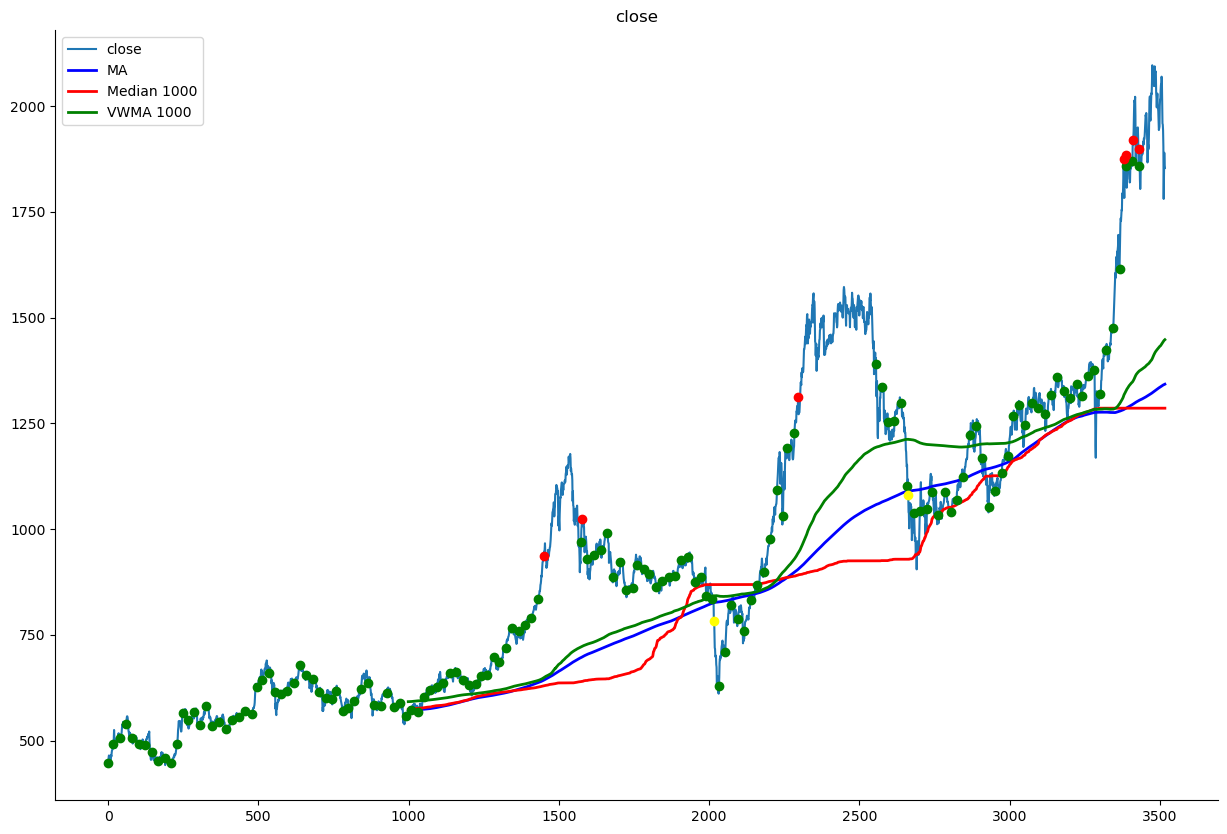

In [219]:

df['close'].plot(kind='line', figsize=(15, 10), title='close')
plt.gca().spines[['top', 'right']].set_visible(False)

df['ma'] = df['close'].rolling(window=1000).mean()
plt.plot(df.index, df['ma'], label='MA', color='blue', linewidth=2)
plt.legend()

df['median_1000'] = df['close'].rolling(window=1000).median()
plt.plot(df.index, df['median_1000'], label='Median 1000', color='red', linewidth=2)
plt.legend()

df['vwma'] = df['close'].rolling(1000).apply(lambda x: (x * df['volume'][x.index]).sum() / df['volume'][x.index].sum(), raw=False)
plt.plot(df.index, df['vwma'], label='VWMA 1000', color='green', linewidth=2)
plt.legend()

for t in buyedInfos:
    color = 'green'
    x_value = t.index
    y_value = df['close'][x_value]
    plt.scatter(t.index, y_value, color=color, zorder=3)
    vertical_offset = 0
    plt.text(
        x_value, 
        y_value + vertical_offset, 
        #f"{round(t['maxMoneyCanInvest']):,}" + "-" + f"{round(t['numberOfStockCanBy'])}",
        "",
        fontsize=10, ha='center', va='bottom',
        bbox=dict(facecolor='white', edgecolor='black', boxstyle='round,pad=0.3')
    )

for t in sellInfos:
    color = 'red'
    y_value = df['close'][t.index]
    plt.scatter(t.index, y_value, color=color, zorder=3)
    vertical_offset = -30
    plt.text(
        t.index, y_value + vertical_offset, 
        #f"{round(t['totalSellMoney']):,}" + "-" + f"{round(t['totalSellStock'])}",
        "",
        fontsize=10, ha='center', va='top',
        bbox=dict(facecolor='white', edgecolor='black', boxstyle='round,pad=0.3')
    )

for t in reinvestInfos:
    color = 'yellow'
    y_value = df['close'][t.index]
    plt.scatter(t.index, y_value, color=color, zorder=3)
    vertical_offset = -30
    plt.text(
        t.index, y_value + vertical_offset, 
        #f"{round(t['totalProfitMoney']):,}",
        "",
        fontsize=10, ha='center', va='top',
        bbox=dict(facecolor='white', edgecolor='black', boxstyle='round,pad=0.3')
    )


plt.show()

In [65]:
firstRow = df.head(1)
firstClose = firstRow['close'].values[0] * 1000
firstDate = firstRow['time'].values[0]
firstDate = pd.Timestamp(firstDate)

lastRow = df.tail(1)
finalClose = lastRow['close'].values[0] * 1000
lastDate = lastRow['time'].values[0]
lastDate = pd.Timestamp(firstDate)

def process(params):
    x, y, i, j = params
    sellTopStrategy = SellTopStrategy()
    sellTopStrategy.percentSell = 70

    sellTopOfBottomStrategy = SellTopOfBottomStrategy(
        firstLocalBottom = firstClose,
        localRangeDays = x,
        percentSell = y,
    )

    sellTopOfMA1000Strategy = SellTopOfMA1000Strategy(
        firstLocalBottom = firstClose,
        percentSell = x,
    )
    
    reInvestBottomStrategy = ReInvestBottomStrategy()
    reInvestBottomStrategy.percentReinvest = 7

    reInvestBottomOfTopStrategy = ReInvestBottomOfTopStrategy(
        firstLocalTop = firstClose,
        localRangeDays = 1000,
        decreasePercent = y,
    )
    reInvestUnderMA1000OrMaxHoldTimeStrategy = ReInvestUnderMA1000OrMaxHoldTimeStrategy(
        maxHoldTime = y,
    )
    
    buyIntervalStrategy = BuyIntervalStrategy()
    buyBottomStrategy = BuyBottomStrategy(
        df = df,
        firstLocalTop = firstClose,
        firstLocalTopDate = firstDate,
        localRangeDays = x,
        decreasePercent = y,
    )
    buyMAStrategy = BuyMAStrategy(
        df = df,
        firstLocalAvg = firstClose,
        localRangeDays = 20,
        decreasePercent = 3,
    )
    buyUptrendStrategy = BuyUptrendStrategy(
        df = df,
        localRangeDays1 = x,
        localRangeDays2 = y,
    )
    
    estimateInfo = estimate(df, 8000000, buyIntervalStrategy, sellTopOfMA1000Strategy, reInvestUnderMA1000OrMaxHoldTimeStrategy, cal_range_close, False)
    allTotalCapital, allTotalFinal, allRatioGrowth, buyedInfos, sellInfos, reinvestInfos = estimateInfo 
    growthRatio = allRatioGrowth
    buyedCount = len(buyedInfos)
    heatMapGrowthRatio[i, j] = growthRatio


In [79]:
x_range = range(90, 150)
y_range = range(10, 2000, 30)

heatMapGrowthRatio = np.zeros((len(x_range), len(y_range)))  # Store results

In [ ]:
for i, x in enumerate(x_range):
    print(f'{x}')
    for j, y in enumerate(y_range):
        params = (x, y, i, j)
        process(params)
    

In [87]:
from concurrent.futures import ThreadPoolExecutor

quads = [
    (i, x, j, y)
    for i, x in enumerate(x_range)
    for j, y in enumerate(y_range)
]

with ThreadPoolExecutor() as executor:
    executor.map(process, quads)

Text(120.72222222222221, 0.5, 'Y')

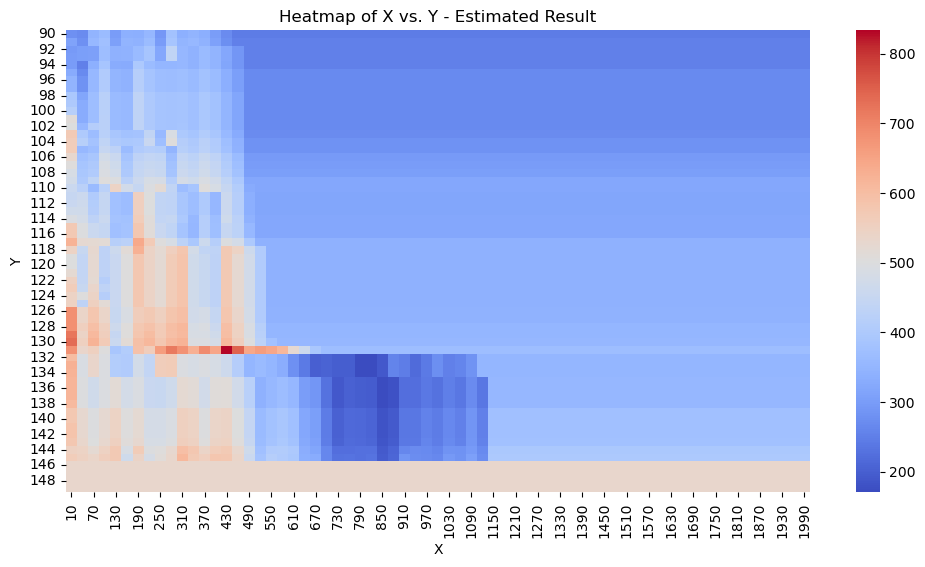

In [83]:
# Convert result matrix to DataFrame
growth_df_results = pd.DataFrame(heatMapGrowthRatio, 
                          index=[f"{p}" for p in x_range], 
                          columns=[f"{d}" for d in y_range])

# Create heatmap
plt.figure(figsize=(12, 6))
sns.heatmap(growth_df_results, annot=False, cmap="coolwarm", fmt=".1f")
plt.title("Heatmap of X vs. Y - Estimated Result")
plt.xlabel("X")
plt.ylabel("Y")


In [ ]:
@dataclass
class GrowRatio:
    x: float = 0
    y: float = 0
    z: float = 0
    t: float = 0
    result: float = 0

In [ ]:
firstRow = df.head(1)
firstClose = firstRow['close'].values[0] * 1000
firstDate = firstRow['time'].values[0]
firstDate = pd.Timestamp(firstDate)

lastRow = df.tail(1)
finalClose = lastRow['close'].values[0] * 1000
lastDate = lastRow['time'].values[0]
lastDate = pd.Timestamp(firstDate)

x_range = range(0, 100)
y_range = range(15, 35)
z_range = range(7, 8)

growRatios = [] 

for i, x in enumerate(x_range):
    print(x)
    for j, y in enumerate(y_range):
        for k, z in enumerate(z_range):
            buyIntervalStrategy = BuyIntervalStrategy()
            
            sellTopOfBottomStrategy = SellTopOfBottomStrategy(
                firstLocalBottom = firstClose,
                localRangeDays = x,
                percentSell = y,
            )
            
            reInvestBottomStrategy = ReInvestBottomStrategy()
            reInvestBottomStrategy.percentReinvest = z

            # if(days == 0 or percent == 0):
            #     buyMAStrategy = BuyIntervalStrategy()

            # if(profit_percent == 0):
            #     sellTopOfBottomStrategy = None

            # if(reinvest_percent == 0):
            #     reInvestBottomStrategy = None

            estimateInfo = estimate(df, 8000000, buyIntervalStrategy, sellTopOfBottomStrategy, reInvestBottomStrategy, cal_range_close, False)
            allTotalCapital, allTotalFinal, allRatioGrowth, buyedInfos, sellInfos, reinvestInfos = estimateInfo 
            
            growthRatio = allRatioGrowth

            growRatios.append(GrowRatio(
                x = x,
                y = y,
                z = z,
                result = growthRatio
            ))

In [ ]:
growRatios

In [ ]:
sorted_data = sorted(growRatios, key=lambda x: x.result, reverse=True)
sorted_data

In [499]:
# Convert result matrix to DataFrame
growth_df_results = pd.DataFrame(heatMapGrowthRatioOfSellAndReinvest, 
                          index=[f"{p}%" for p in percent_profit_range], 
                          columns=[f"{d}" for d in percent_reinvest_range])

# Create heatmap
plt.figure(figsize=(12, 6))
sns.heatmap(growth_df_results, annot=False, cmap="coolwarm", fmt=".1f")
plt.title("Heatmap of sell vs. reinvest - Estimated Result")
plt.ylabel("sell")
plt.xlabel("reinvest")

NameError: name 'heatMapGrowthRatioOfSellAndReinvest' is not defined

In [651]:
growth_df_results.to_excel("growth_df_results.xlsx", sheet_name="Results", index=True)

In [ ]:
df.to_excel("vn30.xlsx", sheet_name="df", index=True)

In [ ]:
df_growthRatio = pd.DataFrame([vars(d) for d in growRatios])

# Save to Excel
df_growthRatio.to_excel("grow_ratios.xlsx", index=False)